# Cross-Sectional Momentum Backtest on 59 ETFs

12-1 month momentum across 59 multi-asset ETFs (Nov 2008 – Sep 2026), with transaction costs, controls against look-ahead bias, an in-sample period for design (2010–2018), an untouched out-of-sample test (2019–Sep 2026) and a year-by-year walk-forward.

**Design frozen before out-of-sample analysis:** 12-1 signal, monthly rebalance, top 20% (12 ETFs) equal weight, long-only, 10 bp costs.

## 1. Data download and checks

Daily adjusted (total-return) closes from Yahoo Finance. The universe was chosen by a fixed rule before looking at returns: broad, liquid, plain-vanilla ETFs launched before November 2008.

In [1]:
#importing the library
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Download daily adjusted closes for the 59 ETFs
# (auto_adjust=True -> prices include dividends, so returns are total returns)
ETF = ["SPY", "QQQ", "IWM", "MDY", "IWD", "IWF", "IJR",
"XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY", "IBB", "IYR", "IYT", "XHB", "XME", "KRE",
"EFA", "EEM", "EWA", "EWC", "EWG", "EWH", "EWJ", "EWU", "EWZ", "EWW", "EWY", "EWT", "EWS", "EWP", "EWI", "EWQ", "EWL", "EWN", "EWD", "EWM", "EZA", "FXI", "ILF",
"TLT", "IEF", "SHY", "LQD", "HYG", "TIP", "AGG", "EMB",
"GLD", "SLV", "USO", "DBC", "DBA",
"VNQ"]
Raw_data = yf.download( ETF , start = "2008-11-01" , end = "2026-10-27" , auto_adjust = True)

[*********************100%***********************]  59 of 59 completed


In [3]:
# Keep only closing prices: rows = dates, columns = ETFs
close = Raw_data["Close"]
print(close.shape)

# Check for ETFs with no data at all
print(close.isna().all().to_string())
# Count missing values per ETF
print(close.isna().sum().to_string())
# Check the date range
print(close.index.min(), close.index.max())
# Save an untouched copy of the raw download (Yahoo revises data over time)
close.to_csv("raw_prices.csv")

# Check the first date with data for each ETF (all must start before end-2008)
for ticker in ETF:
    first_date = close[ticker].first_valid_index()
    print(ticker, first_date)

# Fill short gaps FORWARD only (yesterday's price); never backward, which would be look-ahead
close = close.ffill(limit=5)

# Flag daily moves larger than +/-25% to check by hand (kept if they are real events)
returns = close.pct_change()
big_moves = returns[returns.abs() > 0.25].stack().dropna()
print(big_moves)

close.to_csv("clean_prices.csv")

(4522, 59)
Ticker
AGG    False
DBA    False
DBC    False
EEM    False
EFA    False
EMB    False
EWA    False
EWC    False
EWD    False
EWG    False
EWH    False
EWI    False
EWJ    False
EWL    False
EWM    False
EWN    False
EWP    False
EWQ    False
EWS    False
EWT    False
EWU    False
EWW    False
EWY    False
EWZ    False
EZA    False
FXI    False
GLD    False
HYG    False
IBB    False
IEF    False
IJR    False
ILF    False
IWD    False
IWF    False
IWM    False
IYR    False
IYT    False
KRE    False
LQD    False
MDY    False
QQQ    False
SHY    False
SLV    False
SPY    False
TIP    False
TLT    False
USO    False
VNQ    False
XHB    False
XLB    False
XLE    False
XLF    False
XLI    False
XLK    False
XLP    False
XLU    False
XLV    False
XLY    False
XME    False
Ticker
AGG    0
DBA    0
DBC    0
EEM    0
EFA    0
EMB    0
EWA    0
EWC    0
EWD    0
EWG    0
EWH    0
EWI    0
EWJ    0
EWL    0
EWM    0
EWN    0
EWP    0
EWQ    0
EWS    0
EWT    0
EWU    0
EWW    0
EWY    0
E

## 2. Signal and portfolio weights

Month-end prices → 12-1 momentum signal (return from 12 months ago to 1 month ago) → each month hold the top 20% of ETFs at equal weight.

In [4]:
# Resample daily prices to month-end prices
monthly = close.resample("ME").last()
# Drop the incomplete final month (October 2026)
monthly = monthly.loc[:"2026-09-30"]
print(monthly)

Ticker            AGG        DBA        DBC        EEM         EFA        EMB  \
Date                                                                            
2008-11-30  58.681480  20.816984  18.518942  15.738757   24.373579  33.998310   
2008-12-31  62.591110  22.504150  17.914824  17.365124   26.535128  40.017300   
2009-01-31  61.347633  21.438255  17.120110  15.751704   22.891424  37.230854   
2009-02-28  60.700188  20.303591  16.156315  14.764176   20.513554  35.143696   
2009-03-31  61.369747  21.051437  16.908752  17.253855   22.234848  36.939053   
...               ...        ...        ...        ...         ...        ...   
2026-05-31  97.718010  27.250000  29.480000  68.245277  103.167435  94.790611   
2026-06-30  97.966454  26.670000  26.660000  68.410004  103.879997  95.202248   
2026-07-31  96.696304  27.510000  29.450001  64.089996  105.580002  93.834290   
2026-08-31  97.072998  29.320000  31.299999  67.019997  107.449997  94.355995   
2026-09-30  94.540001  28.13

In [5]:
# 12-1 momentum signal
#signal = price 1 month ago / price 12 month ago -1 
#total 215 month and 59 ETFS
#earliest is 2009/11/30
# shift(n) moves values n rows down, so each row sees the price from n months earlier (positive shift = past only)
signal = monthly.shift(1)/monthly.shift(12)-1
print(signal)
print(signal.shape)

Ticker           AGG       DBA       DBC       EEM       EFA       EMB  \
Date                                                                     
2008-11-30       NaN       NaN       NaN       NaN       NaN       NaN   
2008-12-31       NaN       NaN       NaN       NaN       NaN       NaN   
2009-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2009-02-28       NaN       NaN       NaN       NaN       NaN       NaN   
2009-03-31       NaN       NaN       NaN       NaN       NaN       NaN   
...              ...       ...       ...       ...       ...       ...   
2026-05-31  0.047239  0.087674  0.539593  0.439686  0.193314  0.108161   
2026-06-30  0.035247  0.079647  0.397165  0.442407  0.193635  0.090912   
2026-07-31  0.040626  0.066867  0.227495  0.436360  0.227559  0.088217   
2026-08-31  0.015052  0.026364  0.370607  0.310571  0.193640  0.053652   
2026-09-30  0.007652  0.135180  0.436016  0.279634  0.190192  0.043126   

Ticker           EWA       EWC       

In [6]:
# Hand check: SPY's December 2019 signal should equal its return from end-Dec 2018 to end-Nov 2019
print(monthly.loc["2019-11-30", "SPY"])
print(monthly.loc["2018-12-31", "SPY"])
test =monthly.loc["2019-11-30", "SPY"] / monthly.loc["2018-12-31", "SPY"] -1
print(signal.loc["2019-12-31", "SPY"])
print ( test )

284.3917236328125
223.0195770263672
0.27518726124742576
0.27518726124742576


In [7]:
# Rank ETFs against each other within each month (axis=1 = across the row)
rank = signal.rank(axis=1, pct=True)
# Top 20% = percentile rank above 0.8 (12 of 59 ETFs)
top = rank > 0.8
holding = top.astype(float)
# Equal weight: divide each month's row by the number of ETFs held that month
weight = holding.div(holding.sum(axis=1), axis=0)
# Months before the first signal hold nothing
weight = weight.fillna(0)
weight.to_csv("weights.csv")

In [8]:
# Checks: 12 ETFs held each month, and the top-ranked ETFs are the ones with the highest signal
print(top.sum(axis=1))
print(signal.loc["2019-12-31"].sort_values().tail(5))
print(rank.loc["2019-12-31"].sort_values().tail(5))

Date
2008-11-30     0
2008-12-31     0
2009-01-31     0
2009-02-28     0
2009-03-31     0
              ..
2026-05-31    12
2026-06-30    12
2026-07-31    12
2026-08-31    12
2026-09-30    12
Freq: ME, Length: 215, dtype: int64
Ticker
XLI    0.293447
IWF    0.320482
QQQ    0.337630
XHB    0.422522
XLK    0.436494
Name: 2019-12-31 00:00:00, dtype: float64
Ticker
XLI    0.932203
IWF    0.949153
QQQ    0.966102
XHB    0.983051
XLK    1.000000
Name: 2019-12-31 00:00:00, dtype: float64


## 3. Backtest with transaction costs

Weights set at the end of month *t* earn the return of month *t+1* (one-month lag, the main guard against look-ahead bias). Costs: 10 bp on every unit traded, buys and sells, charged in the month after the trade.

In [9]:
bp = 10                      # transaction cost per unit traded, in basis points
is_start = "2009-12-31"      # first month with holdings
is_end = "2018-12-31"        # last in-sample month

# Return on row t = what happened DURING month t (end of t-1 to end of t).
# Weights on row t are set at the END of month t and held during t+1,
# so weights are shifted down one row to meet the next month's return.
monthly_return = monthly.pct_change()
gross = (monthly_return * weight.shift(1)).sum(axis=1)

# Turnover = total size of buys + sells at each rebalance
turnover = (weight - weight.shift(1)).abs().sum(axis=1)
# In-sample trades: from the first purchase (end-Nov 2009) to the trade that sets up Dec 2018
turnover_is = turnover.loc["2009-11-30":"2018-11-30"]

def net_returns(cost_bps):
    """In-sample net returns at a given cost level (cost charged the month after the trade)."""
    cost = turnover * cost_bps / 10000
    return (gross - cost.shift(1)).loc[is_start:is_end]

net = net_returns(bp)
net_is = net.loc[is_start:is_end]
equity_is = (1 + net_is).cumprod()

# Benchmark: equal weight in all 59 ETFs (same universe, no signal)
bench = monthly_return.mean(axis=1).loc[is_start:]
bench_is = bench.loc[is_start:is_end]
bench_equity_is = (1 + bench_is).cumprod()

In [10]:
#defining functions for analysis

#average year return 
def average_annual_return(r):
    total_growth = (1+r).prod()
    years = len(r)/12
    return total_growth**(1/years)-1
#annual volatility
def annual_volatility( returns):
    return returns.std()*(12**0.5)

#sharpe ratio
#we set risk-free rate = 0
def sharpe(r):
    return average_annual_return(r) / annual_volatility(r)

#max draw down
def drawdown_series(r):
    equity = (1+r).cumprod()
    return equity / equity.cummax()-1
def max_down(r):
    return drawdown_series(r).min()

#hit rate - how often the trade has positive return
def hit_rate(r):
    return (r>0).mean()
#percentage beat bench
def beat_bench(r , b):
    return (r > b).mean()
#annual turnover
def turnover_annual(t):
    return t.mean()*12

## 4. In-sample results (Dec 2009 – Dec 2018)

All design choices were made on this period only.

In [11]:
# In-sample comparison table
table = pd.DataFrame({
    "momentum":{
        "annualised return" : average_annual_return(net_is) ,
        "annual volatility" : annual_volatility(net_is),
        "sharpe ratio": sharpe(net_is),
        "Max drawdown": max_down(net_is),
        "hit rate": hit_rate(net_is),
        "% beat the bench mark" : beat_bench(net_is , bench_is),
        "average annual turnover" : turnover_annual(turnover_is),
    },
    "Benchmark":{
        "annualised return" : average_annual_return(bench_is) ,
        "annual volatility" : annual_volatility(bench_is),
        "sharpe ratio": sharpe(bench_is),
        "Max drawdown": max_down(bench_is),
        "hit rate": hit_rate(bench_is),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }})
print(f"IN-SAMPLE: {net_is.index[0].date()} to {net_is.index[-1].date()} ({len(net_is)} months)\n")
print(table.round(3))

#calculating drag cost
gross_is = gross.loc[is_start:is_end]
print(f"\nCost drag at {bp} bp: "
      f"{(turnover_annual(turnover_is) * bp/10000) * 100:.2f}% per year")
table.to_csv("results_in_sample.csv")

IN-SAMPLE: 2009-12-31 to 2018-12-31 (109 months)

                         momentum  Benchmark
annualised return           0.034      0.060
annual volatility           0.140      0.118
sharpe ratio                0.245      0.509
Max drawdown               -0.276     -0.193
hit rate                    0.587      0.606
% beat the bench mark       0.468        NaN
average annual turnover     6.349        NaN

Cost drag at 10 bp: 0.63% per year


0      0.292
5      0.269
10     0.245
20     0.199
30     0.152
50     0.060
75    -0.053
100   -0.165
dtype: float64


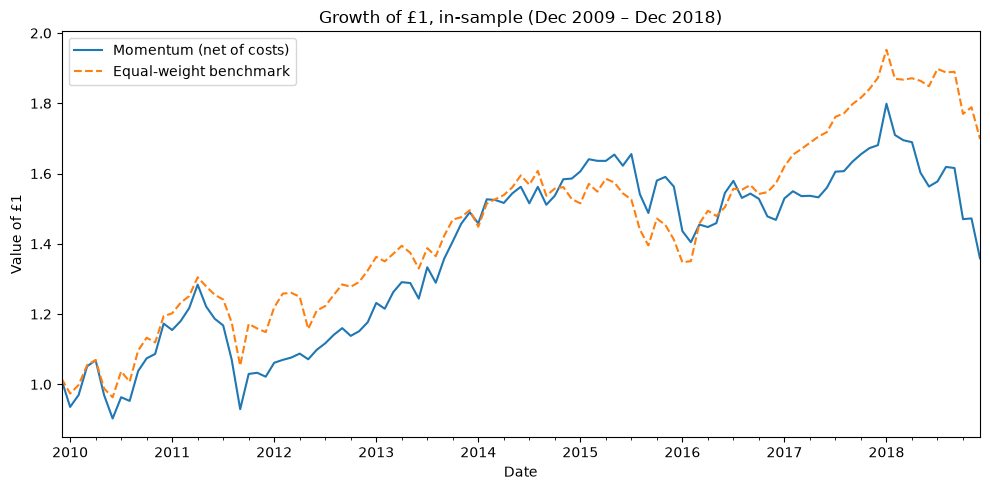

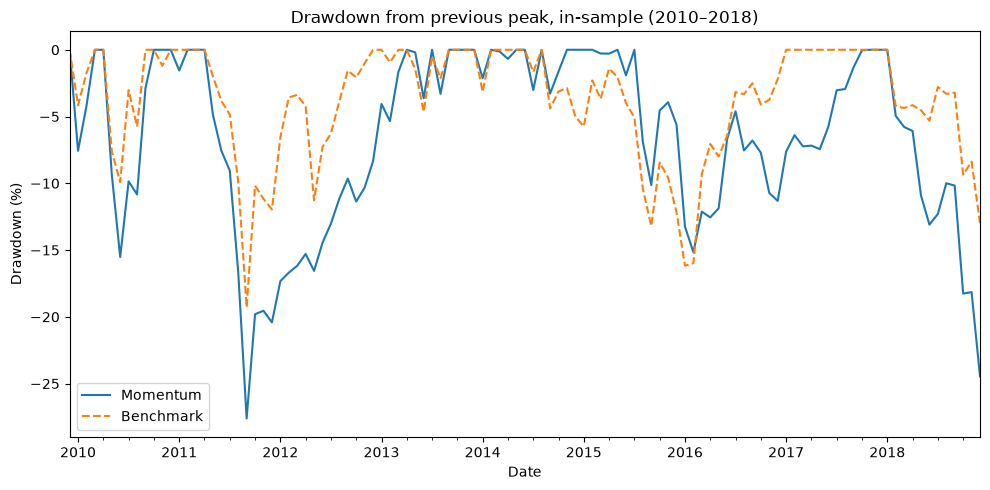

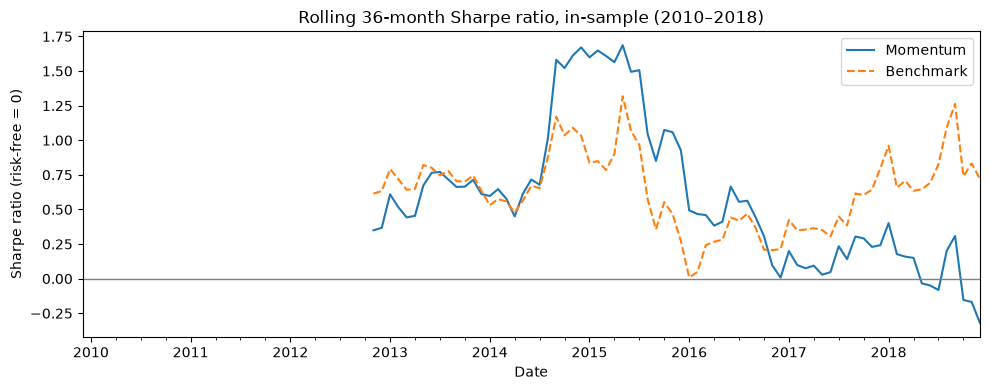

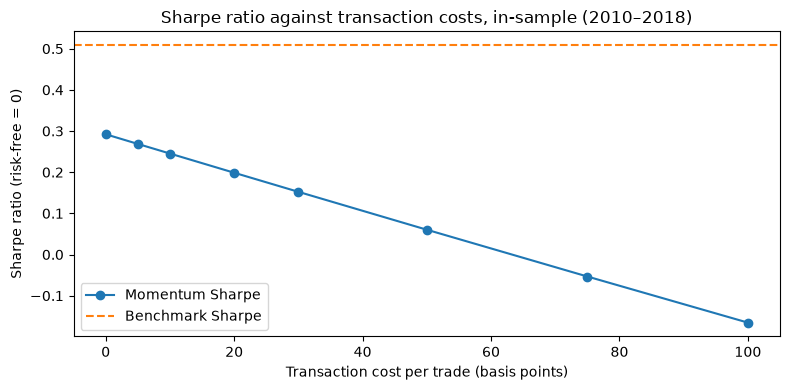

In [12]:
# ---- Chart 1: equity curves, in-sample ----
fig, ax = plt.subplots(figsize=(10, 5))
equity_is.plot(ax=ax, label="Momentum (net of costs)")
bench_equity_is.plot(ax=ax, label="Equal-weight benchmark", linestyle="--")
ax.legend(loc="best")
ax.set_title("Growth of £1, in-sample (Dec 2009 – Dec 2018)")
ax.set_ylabel("Value of £1")
fig.tight_layout()
fig.savefig("chart1_equity_IS.png", dpi=150)

# ---- Chart 2: drawdowns, in-sample ----
fig, ax = plt.subplots(figsize=(10, 5))
(drawdown_series(net_is) * 100).plot(ax=ax, label="Momentum")
(drawdown_series(bench_is) * 100).plot(ax=ax, label="Benchmark", linestyle="--")
ax.legend(loc="best")
ax.set_title("Drawdown from previous peak, in-sample (2010–2018)")
ax.set_ylabel("Drawdown (%)")
fig.tight_layout()
fig.savefig("chart2_drawdown_IS.png", dpi=150)

# ---- Chart 3: rolling 36-month Sharpe, in-sample ----
roll_sharpe = (net_is.rolling(36).mean() * 12) / (net_is.rolling(36).std() * 12 ** 0.5)
roll_sharpe_b = (bench_is.rolling(36).mean() * 12) / (bench_is.rolling(36).std() * 12 ** 0.5)
fig, ax = plt.subplots(figsize=(10, 4))
roll_sharpe.plot(ax=ax, label="Momentum")
roll_sharpe_b.plot(ax=ax, label="Benchmark", linestyle="--")
ax.axhline(0, color="grey", linewidth=1)
ax.legend(loc="best")
ax.set_ylabel("Sharpe ratio (risk-free = 0)")
ax.set_title("Rolling 36-month Sharpe ratio, in-sample (2010–2018)")
fig.tight_layout()
fig.savefig("chart3_rolling_sharpe_IS.png", dpi=150)

# ---- Chart 4: cost sensitivity, in-sample (robustness test, not a parameter to choose) ----
cost_levels = [0, 5, 10, 20, 30, 50, 75, 100]
sharpes = []
for c in cost_levels:
    r = net_returns(c).loc[is_start:is_end]
    sharpes.append(sharpe(r))
print(pd.Series(sharpes, index=cost_levels).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cost_levels, sharpes, marker="o", label="Momentum Sharpe")
ax.axhline(sharpe(bench_is), linestyle="--", color="tab:orange", label="Benchmark Sharpe")
ax.legend(loc="best")
ax.set_xlabel("Transaction cost per trade (basis points)")
ax.set_ylabel("Sharpe ratio (risk-free = 0)")
ax.set_title("Sharpe ratio against transaction costs, in-sample (2010–2018)")
fig.tight_layout()
fig.savefig("chart4_cost_sensitivity_IS.png", dpi=150)
plt.show()

## 5. Out-of-sample results (Jan 2019 – Sep 2026)

The frozen strategy run once on the period set aside at the start. No changes were made after seeing these results.

In [13]:
def net_returns_full_range(cost_bps):
    cost = turnover * cost_bps/10000
    return (gross-cost.shift(1))



# Out-of-sample slices (full-period net returns, then cut from Jan 2019)
# OOS trades: from the trade that sets up Jan 2019 (end-Dec 2018) to the one that sets up Sep 2026
net_oos = (net_returns_full_range(bp)).loc["2019-01-31":]
bench_oos = bench.loc["2019-01-31":]
turnover_oos = turnover.loc["2018-12-31":"2026-08-31"]

# Out-of-sample comparison table
table_oos = pd.DataFrame({
    "momentum":{
        "annualised return" : average_annual_return(net_oos) ,
        "annual volatility" : annual_volatility(net_oos),
        "sharpe ratio": sharpe(net_oos),
        "Max drawdown": max_down(net_oos),
        "hit rate": hit_rate(net_oos),
        "% beat the bench mark" : beat_bench(net_oos , bench_oos),
        "average annual turnover" : turnover_annual(turnover_oos),
    },
    "Benchmark":{
        "annualised return" : average_annual_return(bench_oos) ,
        "annual volatility" : annual_volatility(bench_oos),
        "sharpe ratio": sharpe(bench_oos),
        "Max drawdown": max_down(bench_oos),
        "hit rate": hit_rate(bench_oos),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }})
print(f"OUT OF SAMPLE: {net_oos.index[0].date()} to {net_oos.index[-1].date()} ({len(net_oos)} months)\n")
print(table_oos.round(3))

#calculating drag cost
print(f"\nCost drag at {bp} bp: "
      f"{(turnover_oos.mean()*12 * bp/10000) * 100:.2f}% per year")
table_oos.to_csv("results_out_of_sample.csv")

OUT OF SAMPLE: 2019-01-31 to 2026-09-30 (93 months)

                         momentum  Benchmark
annualised return           0.158      0.118
annual volatility           0.155      0.146
sharpe ratio                1.018      0.807
Max drawdown               -0.155     -0.232
hit rate                    0.656      0.645
% beat the bench mark       0.495        NaN
average annual turnover     5.548        NaN

Cost drag at 10 bp: 0.55% per year


In [14]:
# In-sample vs out-of-sample, side by side
table_compare = pd.DataFrame({
    ("Out of sample" ,"momentum"):{
        "annualised return" : average_annual_return(net_oos) ,
        "annual volatility" : annual_volatility(net_oos),
        "sharpe ratio": sharpe(net_oos),
        "Max drawdown": max_down(net_oos),
        "hit rate": hit_rate(net_oos),
        "% beat the bench mark" : beat_bench(net_oos ,bench_oos),
        "average annual turnover" : turnover_annual(turnover_oos)},
       ("Out of sample" ,"Benchmark"):{
        "annualised return" : average_annual_return(bench_oos) ,
        "annual volatility" : annual_volatility(bench_oos),
        "sharpe ratio": sharpe(bench_oos),
        "Max drawdown": max_down(bench_oos),
        "hit rate": hit_rate(bench_oos),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }, 
        ("In sample" ,"momentum"):{
        "annualised return" : average_annual_return(net_is) ,
        "annual volatility" : annual_volatility(net_is),
        "sharpe ratio": sharpe(net_is),
        "Max drawdown": max_down(net_is),
        "hit rate": hit_rate(net_is),
        "% beat the bench mark" : beat_bench(net_is , bench_is),
        "average annual turnover" : turnover_annual(turnover_is),
    },
    ("In sample" ,"Benchmark"):{
        "annualised return" : average_annual_return(bench_is) ,
        "annual volatility" : annual_volatility(bench_is),
        "sharpe ratio": sharpe(bench_is),
        "Max drawdown": max_down(bench_is),
        "hit rate": hit_rate(bench_is),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }})

print(table_compare)
table_compare.to_csv("results_compare.csv")

                        Out of sample           In sample          
                             momentum Benchmark  momentum Benchmark
annualised return            0.158027  0.118168  0.034326  0.060079
annual volatility            0.155177  0.146401  0.139931  0.118148
sharpe ratio                 1.018368  0.807159  0.245303  0.508508
Max drawdown                -0.154786 -0.231729 -0.276155 -0.192923
hit rate                     0.655914  0.645161  0.587156  0.605505
% beat the bench mark        0.494624       NaN  0.467890       NaN
average annual turnover      5.548387       NaN  6.348624       NaN


0      1.059
5      1.039
10     1.018
20     0.978
30     0.937
50     0.857
75     0.757
100    0.658
dtype: float64


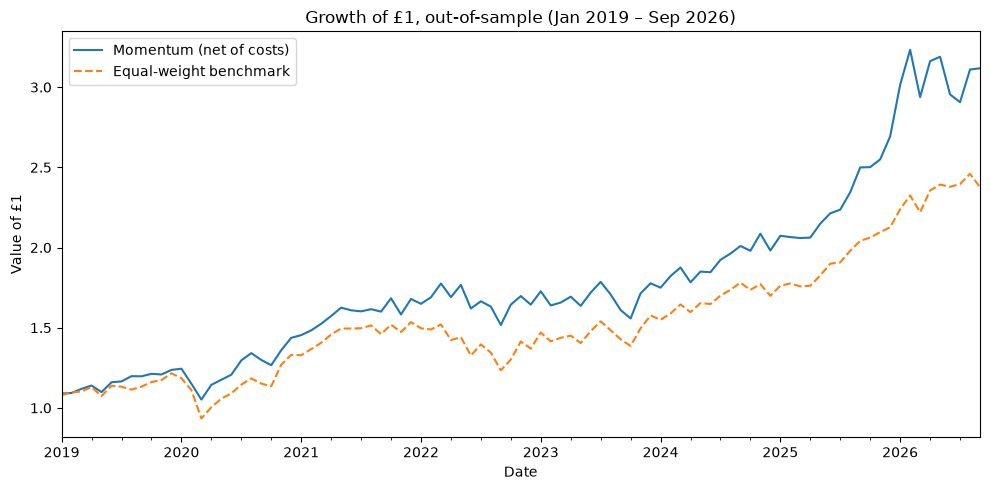

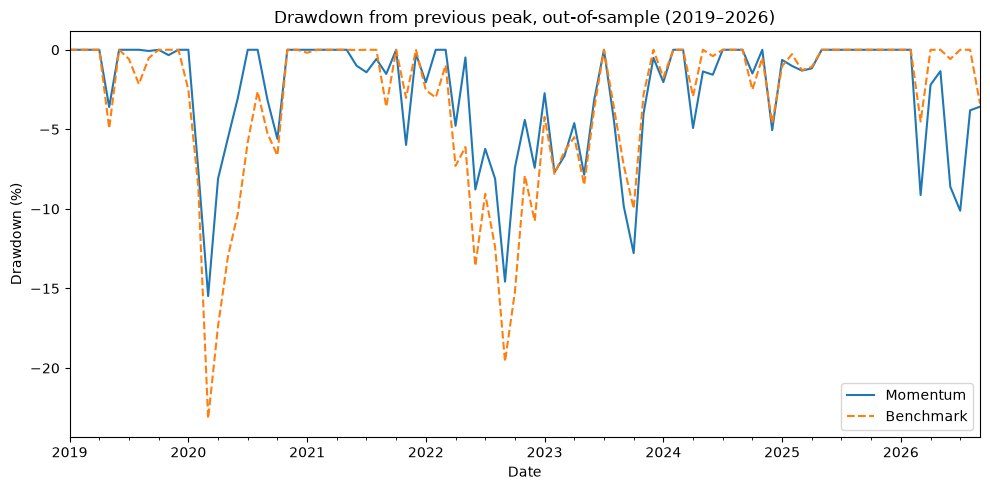

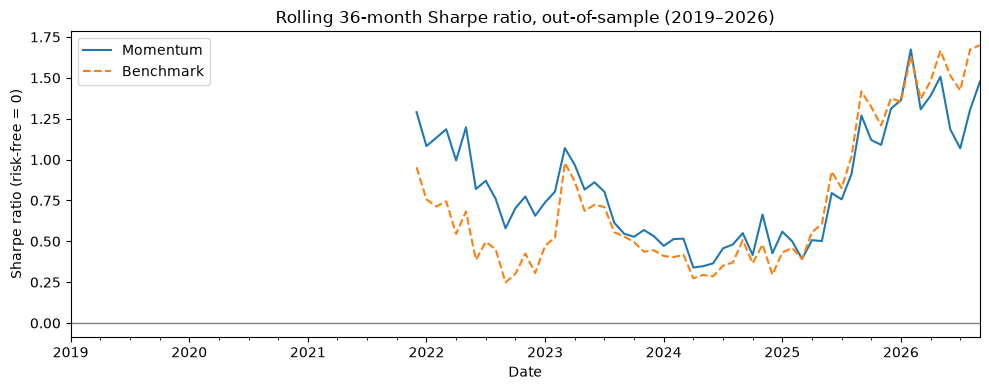

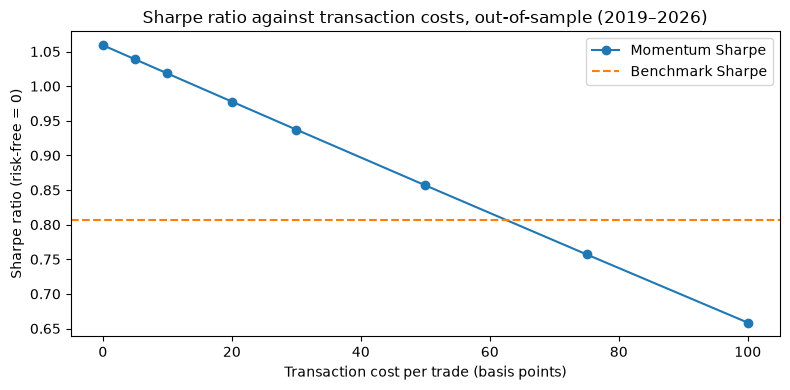

In [15]:
# ---- Chart 1: equity curves, out-of-sample ----
equity_oos = (1 + net_oos).cumprod()
bench_equity_oos = (1 + bench_oos).cumprod()
fig, ax = plt.subplots(figsize=(10, 5))
equity_oos.plot(ax=ax, label="Momentum (net of costs)")
bench_equity_oos.plot(ax=ax, label="Equal-weight benchmark", linestyle="--")
ax.legend(loc="best")
ax.set_title("Growth of £1, out-of-sample (Jan 2019 – Sep 2026)")
ax.set_ylabel("Value of £1")
fig.tight_layout()
fig.savefig("chart1_equity_OOS.png", dpi=150)

# ---- Chart 2: drawdowns, out-of-sample ----
fig, ax = plt.subplots(figsize=(10, 5))
(drawdown_series(net_oos) * 100).plot(ax=ax, label="Momentum")
(drawdown_series(bench_oos) * 100).plot(ax=ax, label="Benchmark", linestyle="--")
ax.legend(loc="best")
ax.set_title("Drawdown from previous peak, out-of-sample (2019–2026)")
ax.set_ylabel("Drawdown (%)")
fig.tight_layout()
fig.savefig("chart2_drawdown_OOS.png", dpi=150)

# ---- Chart 3: rolling 36-month Sharpe, out-of-sample ----
roll_sharpe_oos = (net_oos.rolling(36).mean() * 12) / (net_oos.rolling(36).std() * 12 ** 0.5)
roll_sharpe_b_oos = (bench_oos.rolling(36).mean() * 12) / (bench_oos.rolling(36).std() * 12 ** 0.5)
fig, ax = plt.subplots(figsize=(10, 4))
roll_sharpe_oos.plot(ax=ax, label="Momentum")
roll_sharpe_b_oos.plot(ax=ax, label="Benchmark", linestyle="--")
ax.axhline(0, color="grey", linewidth=1)
ax.legend(loc="best")
ax.set_ylabel("Sharpe ratio (risk-free = 0)")
ax.set_title("Rolling 36-month Sharpe ratio, out-of-sample (2019–2026)")
fig.tight_layout()
fig.savefig("chart3_rolling_sharpe_OOS.png", dpi=150)

# ---- Chart 4: cost sensitivity, out-of-sample ----
sharpes_oos = []
for c in cost_levels:
    r = net_returns_full_range(c).loc["2019-01-31":]   # out-of-sample only
    sharpes_oos.append(sharpe(r))
print(pd.Series(sharpes_oos, index=cost_levels).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cost_levels, sharpes_oos, marker="o", label="Momentum Sharpe")
ax.axhline(sharpe(bench_oos), linestyle="--", color="tab:orange", label="Benchmark Sharpe")
ax.legend(loc="best")
ax.set_xlabel("Transaction cost per trade (basis points)")
ax.set_ylabel("Sharpe ratio (risk-free = 0)")
ax.set_title("Sharpe ratio against transaction costs, out-of-sample (2019–2026)")
fig.tight_layout()
fig.savefig("chart4_cost_sensitivity_OOS.png", dpi=150)
plt.show()

## 6. Walk-forward: year by year

The strategy has no fitted parameters, so walk-forward here means testing it one calendar year at a time: are results consistent, or driven by a few years?

Year-by-year returns (%). Note: 2026 is a partial year (Jan-Sep).

      Momentum  Benchmark  Difference  Momentum won         Period
Date                                                              
2010      15.9       17.5        -1.7         False      In-sample
2011     -12.9       -3.8        -9.1         False      In-sample
2012      15.2       15.3        -0.1         False      In-sample
2013      26.6       12.9        13.6          True      In-sample
2014       6.5        2.1         4.4          True      In-sample
2015      -1.5       -7.5         6.1          True      In-sample
2016      -6.1       11.4       -17.4         False      In-sample
2017      14.5       19.1        -4.6         False      In-sample
2018     -19.2       -9.3        -9.9         False      In-sample
2019      23.7       21.6         2.1          True  Out-of-sample
2020      16.2        9.5         6.7          True  Out-of-sample
2021      16.9       15.3         1.5          True  Out-of-sa

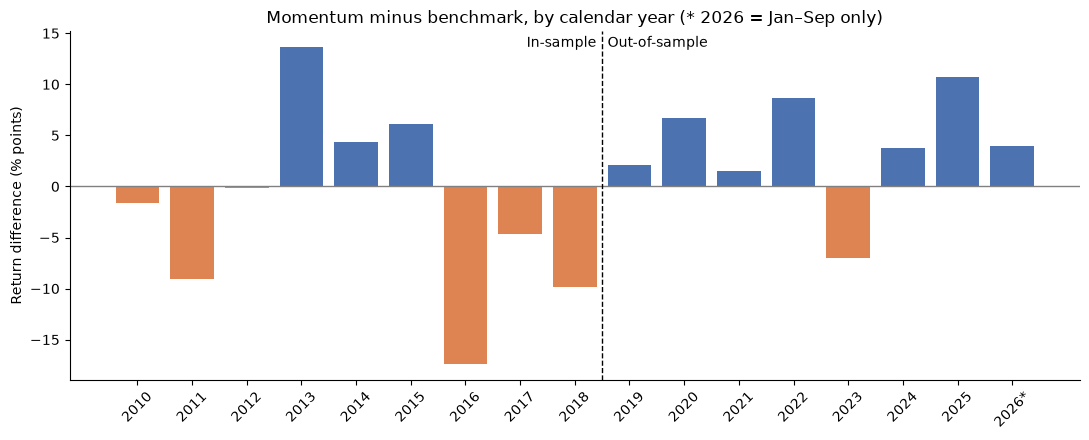

In [16]:
# Full-period monthly returns (Dec 2009 - Sep 2026), at the frozen 10 bp
net_full = net_returns_full_range(bp).loc[is_start:]
bench_full = bench.loc[is_start:]


def compound(r):
    """Turn one year's monthly returns into that year's total return."""
    return (1 + r).prod() - 1


# Group the months into calendar years and compound each year
# ("YE" = year-end; use "Y" if your pandas version is older)
yearly = pd.DataFrame({
    "Momentum": net_full.resample("YE").apply(compound),
    "Benchmark": bench_full.resample("YE").apply(compound),
})
yearly.index = yearly.index.year      # 2010-12-31 -> 2010, easier to read
yearly = yearly.loc[2010:]            # drop 2009: only 1 month (Dec)

yearly["Difference"] = yearly["Momentum"] - yearly["Benchmark"]
yearly["Momentum won"] = yearly["Difference"] > 0
yearly["Period"] = ["In-sample" if y <= 2018 else "Out-of-sample" for y in yearly.index]

print("Year-by-year returns (%). Note: 2026 is a partial year (Jan-Sep).\n")
show = (yearly[["Momentum", "Benchmark", "Difference"]] * 100).round(1)
print(show.join(yearly[["Momentum won", "Period"]]).to_string())

# ---- Summary: how consistent was momentum in each period? ----
summary = yearly.groupby("Period").agg(
    years=("Difference", "size"),
    years_won=("Momentum won", "sum"),
    avg_difference=("Difference", "mean"),
    best_year=("Difference", "max"),
    worst_year=("Difference", "min"),
)
summary["win_rate"] = summary["years_won"] / summary["years"]
print("\nSummary by period:")
print(summary.round(3).to_string())

# ---- Concentration check: does the OOS win depend on one or two years? ----
oos = yearly.loc[yearly["Period"] == "Out-of-sample", "Difference"]
print("\nOut-of-sample yearly differences, best to worst (%):")
print((oos.sort_values(ascending=False) * 100).round(1).to_string())
print(f"\nAverage OOS difference: {oos.mean() * 100:.1f}% a year")
print(f"Without the single best year: {oos.drop(oos.idxmax()).mean() * 100:.1f}% a year")

yearly.to_csv("results_yearly_walk_forward.csv")

# ---- Chart: yearly difference, momentum minus benchmark ----
colours = ["#4C72B0" if d > 0 else "#DD8452" for d in yearly["Difference"]]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(yearly.index, yearly["Difference"] * 100, color=colours)
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(2018.5, color="black", linestyle="--", linewidth=1)   # IS / OOS split
ax.text(2018.4, ax.get_ylim()[1] * 0.9, "In-sample", ha="right")
ax.text(2018.6, ax.get_ylim()[1] * 0.9, "Out-of-sample", ha="left")
ax.set_xticks(yearly.index)
ax.set_xticklabels([f"{y}*" if y == 2026 else str(y) for y in yearly.index], rotation=45)
ax.set_title("Momentum minus benchmark, by calendar year (* 2026 = Jan–Sep only)")
ax.set_ylabel("Return difference (% points)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("chart_yearly_difference.png", dpi=150)
plt.show()